<a href="https://colab.research.google.com/github/teixeirackayky29/Desafio_01_Telemetria_esportiva/blob/main/api/Desafio2_Estatistica_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [49]:
# ---------- Bibliotecas: ferramentas prontas que o Python usa ----------
import warnings                    # esconde avisos técnicos para não distrair
from pathlib import Path           # manipula caminhos de arquivos e pastas
import shutil                      # manipula arquivos e pastas (ex.: mover, copiar, apagar)

# Estas linhas servem para trabalhar no Google Colab (conectar ao Drive e enviar arquivos)
from google.colab import drive     # conecta o Google Drive ao Colab (para ler e salvar arquivos)
from google.colab import files     # (files) envia arquivos do seu computador para o Colab

# Bibliotecas de análise de dados e de gráficos
import pandas as pd                # tabelas de dados (DataFrame)
import seaborn as sns              # gráficos bonitos e simples
import matplotlib.pyplot as plt    # ajustes nos gráficos (título, linhas...)

# ---------- Configurações gerais (valem para todos os gráficos abaixo) ----------
warnings.filterwarnings("ignore")           # esconde avisos técnicos para não distrair
sns.set_theme(style="whitegrid")            # deixa todos os gráficos com um visual limpo
plt.rcParams["figure.figsize"] = (8, 6)    # tamanho padrão dos gráficos (largura, altura)

###Carregar os dados

In [50]:
# Nomes das tabelas do seu tema (veja a tabela acima), iguais aos nomes dos arquivos CSV.
NOME_TABELA_DIMENSAO = "pilotos"   # ex.: "livros"
NOME_TABELA_FATO = "voltas"           # ex.: "emprestimos"

# ---------- 1) Conectando ao Google Drive ----------
drive.mount("/content/drive")      # vai pedir autorização na primeira vez

# ---------- 2) Dizendo onde os arquivos estão guardados ----------
pasta_dados = Path("/content/drive/MyDrive/Colab Notebooks/desafios/dados")   # pasta onde a base fica guardada no Drive
pasta_dados.mkdir(parents=True, exist_ok=True)                                # cria a pasta "dados" se faltar

# O "/" junta a pasta com o nome do arquivo (o nome vem da variável de cada tabela).
caminho_dimensao = pasta_dados / f"{NOME_TABELA_DIMENSAO}.csv"
caminho_fato = pasta_dados / f"{NOME_TABELA_FATO}.csv"

# ---------- 3) Se faltar algum arquivo, envia os dois de uma vez e o código separa ----------
if not caminho_dimensao.exists() or not caminho_fato.exists():
    print(f"Selecione os arquivos CSV ({NOME_TABELA_DIMENSAO} e {NOME_TABELA_FATO}). Pode escolher os dois de uma vez:")
    enviados = files.upload()                                  # abre o seletor; aceita vários arquivos

    for nome_enviado in enviados:                              # percorre cada arquivo enviado
        if NOME_TABELA_DIMENSAO in nome_enviado.lower():       # o nome contém o da dimensão? salva como dimensão
            shutil.move(nome_enviado, caminho_dimensao)        # salva já com o nome da tabela
            print(f"{nome_enviado} -> {caminho_dimensao.name}")
        elif NOME_TABELA_FATO in nome_enviado.lower():         # o nome contém o da fato? salva como fato
            shutil.move(nome_enviado, caminho_fato)
            print(f"{nome_enviado} -> {caminho_fato.name}")
        else:                                                  # nome que não combina com nenhuma tabela
            print(f"Ignorado: {nome_enviado} (o nome não contém '{NOME_TABELA_DIMENSAO}' nem '{NOME_TABELA_FATO}')")

# Confere se os dois arquivos estão no Drive antes de ler.
for caminho in [caminho_dimensao, caminho_fato]:
    if not caminho.exists():
        raise FileNotFoundError(f"Falta o arquivo {caminho.name}. Execute a célula de novo e envie-o.")

# ---------- 4) Lendo os dois arquivos ----------
df_dimensao = pd.read_csv(caminho_dimensao)
df_fato = pd.read_csv(caminho_fato)

print(NOME_TABELA_DIMENSAO, "->", len(df_dimensao), "linhas")
print(NOME_TABELA_FATO, "->", len(df_fato), "linhas")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
pilotos -> 10800 linhas
voltas -> 55000 linhas


###Conhecendo a tabela dimensão


In [51]:
# Quantas linhas (registros do cadastro) e colunas (variáveis) tem a tabela dimensão?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_dimensao.shape
print(f"A tabela dimensão tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_dimensao.head())

A tabela dimensão tem 10800 linhas e 5 colunas (variáveis)


,piloto_id,nome,equipe,categoria,pais
0,1,NitroMax3329,Equipe Eligendi Racing,rally_sim,Estados Unidos
1,2,ApexPrime5103,Equipe Incidunt Racing,stock_sim,Estados Unidos
2,3,VortexElite3872,Equipe Fugiat Racing,kart,Brasil
3,4,StormX714,Equipe Facilis Racing,kart,México
4,5,FastGT6668,Equipe Eaque Racing,stock_sim,Alemanha


###Conhecendo a tabela fato

In [52]:
# Quantas linhas (eventos) e colunas (variáveis) tem a tabela fato?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_fato.shape
print(f"A tabela fato tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_fato.head())

A tabela fato tem 55000 linhas e 9 colunas (variáveis)


,volta_id,piloto_id,corrida_id,numero_volta,status_volta,tempo_volta_seg,velocidade_media_kmh,combustivel_restante_pct,posicao_na_volta
0,1,1389,1,1,normal,110.286,100.0,91.7,6
1,2,4676,1,1,normal,108.967,101.2,92.8,4
2,3,1002,1,1,normal,107.934,102.2,91.1,1
3,4,1054,1,1,normal,111.375,99.0,91.9,7
4,5,3726,1,1,normal,111.825,98.6,92.9,10


### Pergunta que eu quero responder:

O tempo de volta é consistente ou varia de acordo com o tipo de volta e a categoria do piloto?

**Principais insights:**

A análise dos 55 mil registros revelou uma variação considerável nos tempos de volta, com média de 83,15 segundos e desvio padrão de 20,40 segundos.

Também foi possível observar que 75% dos tempos ficaram abaixo ou iguais a 96,95 segundos e 90% abaixo ou iguais a 108,88 segundos.

Outro ponto interessante foi a aplicação da regra do IQR, que não identificou candidatos a outliers, permitindo manter todos os registros nessa etapa.

A próxima investigação consiste em comparar os resultados por tipo de volta e categoria dos pilotos, buscando identificar diferenças de desempenho e consistência entre os grupos.

# Célula 05 - Tipos das colunas

In [53]:
# 1) Tipo de cada coluna e quantidade de valores preenchidos. Compare com o esquema do plano do tema.
df_fato.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55000 entries, 0 to 54999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   volta_id                  55000 non-null  int64  
 1   piloto_id                 55000 non-null  int64  
 2   corrida_id                55000 non-null  int64  
 3   numero_volta              55000 non-null  int64  
 4   status_volta              55000 non-null  object 
 5   tempo_volta_seg           55000 non-null  float64
 6   velocidade_media_kmh      55000 non-null  float64
 7   combustivel_restante_pct  55000 non-null  float64
 8   posicao_na_volta          55000 non-null  int64  
dtypes: float64(3), int64(5), object(1)
memory usage: 3.8+ MB


### Célula 06 · Valores ausentes


In [54]:
# 2) Valores ausentes por coluna (tabela fato).
print("\nValores ausentes por coluna:")
print(df_fato.isna().sum())


Valores ausentes por coluna:
volta_id                    0
piloto_id                   0
corrida_id                  0
numero_volta                0
status_volta                0
tempo_volta_seg             0
velocidade_media_kmh        0
combustivel_restante_pct    0
posicao_na_volta            0
dtype: int64


###Célula 07 · Linhas duplicadas


In [55]:
# 3) Linhas duplicadas (tabela fato).
print("\nLinhas duplicadas:", df_fato.duplicated().sum())


Linhas duplicadas: 0


Célula 08 · Chave estrangeira


In [56]:
# 4) Chave estrangeira: todos os registros da tabela fato devem apontar para um ID que existe na tabela dimensão.
COLUNA_FK = "piloto_id"        # ex.: "livro_id" (coluna da fato que referencia a dimensão)
COLUNA_ID = "piloto_id"   # ex.: "livro_id" (coluna de ID da dimensão)
print("\nChaves estrangeiras que batem:", df_fato[COLUNA_FK].isin(df_dimensao[COLUNA_ID]).all())


Chaves estrangeiras que batem: True


Célula 09 · Checar a coluna numérica

In [57]:
# Colunas numéricas escolhidas
COLUNA_NUMERICA = "tempo_volta_seg"
COLUNA_NUMERICA_2 = "posicao_na_volta"

# Primeira variável: tempo de volta
serie_numerica = df_fato[COLUNA_NUMERICA]

# Segunda variável: posição na volta
serie_numerica_2 = df_fato[COLUNA_NUMERICA_2]

print("TEMPO DE VOLTA")
print("Valores preenchidos:", serie_numerica.count(),
      "| ausentes:", serie_numerica.isna().sum())

print("\nPOSIÇÃO NA VOLTA")
print("Valores preenchidos:", serie_numerica_2.count(),
      "| ausentes:", serie_numerica_2.isna().sum())

TEMPO DE VOLTA
Valores preenchidos: 55000 | ausentes: 0

POSIÇÃO NA VOLTA
Valores preenchidos: 55000 | ausentes: 0


Célula 10 · Medidas estatísticas

In [58]:
def calcular_medidas(serie_numerica):
    medidas = pd.Series({
        "Média": serie_numerica.mean(),
        "Mediana": serie_numerica.median(),
        "Moda": serie_numerica.mode()[0],
        "Desvio padrão": serie_numerica.std(),
        "Variância": serie_numerica.var(),
        "Mínimo": serie_numerica.min(),
        "Máximo": serie_numerica.max(),
        "Amplitude": serie_numerica.max() - serie_numerica.min(),
    }).round(2)

    display(medidas)

    print("Média - mediana:",
          round(medidas["Média"] - medidas["Mediana"], 2))


# Análise do tempo de volta
print("ANÁLISE: TEMPO DE VOLTA")
calcular_medidas(serie_numerica)

# Análise da posição na volta
print("\nANÁLISE: POSIÇÃO NA VOLTA")
calcular_medidas(serie_numerica_2)

ANÁLISE: TEMPO DE VOLTA


,0
Média,83.15
Mediana,87.51
Moda,88.99
Desvio padrão,20.40
Variância,416.24
Mínimo,41.42
Máximo,148.29
Amplitude,106.87


Média - mediana: -4.36

ANÁLISE: POSIÇÃO NA VOLTA


,0
Média,5.50
Mediana,5.50
Moda,1.00
Desvio padrão,2.87
Variância,8.25
Mínimo,1.00
Máximo,10.00
Amplitude,9.00


Média - mediana: 0.0


Célula 11 · Juntar a fato com a dimensão

In [59]:
# Junta a fato com a dimensão: cada registro da fato recebe as colunas do seu cadastro.
df_completo = df_fato.merge(df_dimensao, left_on=COLUNA_FK, right_on=COLUNA_ID, how="left", suffixes=("", "_dim"))

print("Linhas da fato:", len(df_fato), "| depois da junção:", len(df_completo))   # precisam ser iguais

Linhas da fato: 55000 | depois da junção: 55000


In [60]:
df_completo.head()

,volta_id,piloto_id,corrida_id,numero_volta,status_volta,tempo_volta_seg,velocidade_media_kmh,combustivel_restante_pct,posicao_na_volta,nome,equipe,categoria,pais
0,1,1389,1,1,normal,110.286,100.0,91.7,6,BlazeOne5318,Equipe Aut Racing,rally_sim,Japão
1,2,4676,1,1,normal,108.967,101.2,92.8,4,BlazeRS3149,Equipe Suscipit Racing,rally_sim,Brasil
2,3,1002,1,1,normal,107.934,102.2,91.1,1,FastX6616,Equipe Impedit Racing,rally_sim,Japão
3,4,1054,1,1,normal,111.375,99.0,91.9,7,StormPrime5176,Equipe Iure Racing,rally_sim,Espanha
4,5,3726,1,1,normal,111.825,98.6,92.9,10,ApexZero929,Equipe Asperiores Racing,rally_sim,Brasil


Célula 12 · Comparar grupos por uma coluna da fato

In [61]:
COLUNA_GRUPO = "categoria"
COLUNA_NUMERICA = "tempo_volta_seg"

por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(
    ["count", "mean", "median", "std"]
).round(2)

por_grupo = por_grupo.sort_values("mean", ascending=False)

display(por_grupo)

,count,mean,median,std
categoria,,,,
rally_sim,7950,110.76,110.00,5.91
stock_sim,15100,95.73,95.25,5.85
formula_sim,15400,85.89,85.42,6.34
kart,16550,55.86,55.19,5.97


# Generated-by: AI (OpenAI ChatGPT)
# AI-Generated-Date: 2026-11-16
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT



A categoria rally_sim apresentou a maior média de tempo de volta (110,76 segundos), seguida de stock_sim (95,73), formula_sim (85,89) e kart (55,86). As medianas acompanham essa tendência, confirmando que a diferença entre os tempos não é explicada apenas por valores extremos.

A categoria formula_sim apresentou o maior desvio padrão (6,34 segundos), indicando maior dispersão nos tempos de volta. Já stock_sim apresentou a menor dispersão (5,85 segundos), sugerindo maior regularidade nos tempos.

As médias apresentam diferenças consideráveis entre as categorias, indicando que o tipo de modalidade está associado a padrões distintos de tempo de volta. Isso pode estar relacionado às características de cada categoria, como velocidade e condições de corrida.

Insight principal: a categoria parece estar relacionada às diferenças nos tempos de volta, enquanto a dispersão dentro de cada categoria é relativamente semelhante.

Célula 13 · Comparar grupos por uma coluna da dimensão

In [62]:
COLUNA_GRUPO = "categoria"     # coluna da dimensão: só existe em df_completo por causa da junção

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
categoria,,,,
rally_sim,7950,110.76,110.00,5.91
stock_sim,15100,95.73,95.25,5.85
formula_sim,15400,85.89,85.42,6.34
kart,16550,55.86,55.19,5.97


Célula 14 · Regra do IQR

In [63]:
# Faixa central dos dados: do 1º ao 3º quartil (25% e 75%).
q1 = serie_numerica.quantile(0.25)
q3 = serie_numerica.quantile(0.75)
iqr = q3 - q1

# Regra usual: fora de [Q1 - 1,5 x IQR ; Q3 + 1,5 x IQR] é candidato a outlier.
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Cálculo do número de outliers
sem_outliers = serie_numerica[(serie_numerica >= limite_inferior) & (serie_numerica <= limite_superior)]
qtd_outliers = serie_numerica.count() - sem_outliers.count()

print(f"Limites: {limite_inferior:.2f} a {limite_superior:.2f}")
print(f"Outliers: {qtd_outliers} de {serie_numerica.count()} valores")
print("Maiores valores:", serie_numerica.nlargest(5).tolist())
print("Menores valores:", serie_numerica.nsmallest(5).tolist())

Limites: 4.15 a 152.63
Outliers: 0 de 55000 valores
Maiores valores: [148.295, 146.716, 145.777, 145.109, 144.853]
Menores valores: [41.424, 41.542, 42.09, 42.149, 42.15]


Célula 15 · Medidas com e sem os candidatos a outlier

In [66]:
# Compara as medidas com e sem os candidatos a outlier.
comparacao = pd.DataFrame({
    "Com outliers": [serie_numerica.mean(), serie_numerica.median(), serie_numerica.std()],
    "Sem outliers": [sem_outliers.mean(), sem_outliers.median(), sem_outliers.std()],
}, index=["Média", "Mediana", "Desvio padrão"]).round(2)
display(comparacao)




,Com outliers,Sem outliers
Média,83.15,83.15
Mediana,87.51,87.51
Desvio padrão,20.40,20.40


Leitura e decisão registrada
Outliers (regra do IQR):
- Quantidade identificada: 0 de 55.000 valores.
- Limites calculados: 4,15 a 152,63 segundos.
- Nenhum tempo de volta ficou fora desses limites.
- Média: permaneceu em 83,15 segundos.
- Mediana: permaneceu em 87,51 segundos.
- Desvio padrão: permaneceu em 20,40 segundos.
Decisão: Manter todos os registros, pois nenhum valor foi identificado como candidato a outlier pela regra do IQR. A comparação confirmou que a filtragem não alterou as medidas estatísticas.

Valores ausentes: ainda precisamos confirmar o tratamento realizado. Se você verificou que não existem valores ausentes em tempo_volta_seg, registre:
- Quantidade de valores ausentes: 0.
- Tratamento: não foi necessária nenhuma alteração.
- Justificativa: todos os registros possuem valores preenchidos nessa variável.

Célula 16 · Assimetria (skew)

In [67]:
# Assimetria: perto de 0 = formato equilibrado; positiva = cauda para valores altos; negativa = para valores baixos.
print("Assimetria:", round(serie_numerica.skew(), 2))

Assimetria: -0.25


Célula 17 · Percentis


In [68]:
# Coluna que será analisada
COLUNA_NUMERICA = "tempo_volta_seg"

# Seleciona a série numérica
serie_numerica = df_fato[COLUNA_NUMERICA]

# Calcula os percentis
percentis = serie_numerica.quantile([0.10, 0.25, 0.50, 0.75, 0.90])

print(f"ANÁLISE DE PERCENTIS: {COLUNA_NUMERICA}")
print("-" * 45)

print(f"Percentil 10%: {percentis.loc[0.10]:.2f} segundos")
print(f"Percentil 25%: {percentis.loc[0.25]:.2f} segundos")
print(f"Percentil 50%: {percentis.loc[0.50]:.2f} segundos")
print(f"Percentil 75%: {percentis.loc[0.75]:.2f} segundos")
print(f"Percentil 90%: {percentis.loc[0.90]:.2f} segundos")

ANÁLISE DE PERCENTIS: tempo_volta_seg
---------------------------------------------
Percentil 10%: 53.25 segundos
Percentil 25%: 59.83 segundos
Percentil 50%: 87.51 segundos
Percentil 75%: 96.95 segundos
Percentil 90%: 108.88 segundos


Célula 18 · Quantidade de valores por faixa

In [69]:
# Quantidade de valores em 5 faixas de mesmo tamanho (a versão em texto de um histograma).
display(pd.cut(serie_numerica, bins=5).value_counts().sort_index())

,count
tempo_volta_seg,
"(41.317, 62.798]",15392
"(62.798, 84.172]",7269
"(84.172, 105.547]",24576
"(105.547, 126.921]",7524
"(126.921, 148.295]",239


# Generated-by: AI (OpenAI ChatGPT)
# AI-Generated-Date: 2026-11-16
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT


**Pergunta de negócio:** O tempo de volta é consistente ou varia de acordo com o tipo de volta e a categoria do piloto?

**Evidência 1:** A média do tempo de volta foi de 83,15 segundos, enquanto a mediana foi de 87,51 segundos. Essa diferença indica que os tempos mais baixos influenciam a média.

**Evidência 2:** O desvio padrão foi de 20,40 segundos, indicando uma dispersão considerável dos tempos em relação à média.

**Recomendação em uma frase:** Investigar quais tipos de volta e categorias de pilotos apresentam maiores tempos e variações, para identificar oportunidades de melhorar a consistência e o desempenho nas corridas.

**Limites da análise:** Os dados utilizados são fictícios e representam uma simulação. Pela regra do IQR, nenhum dos 55.000 registros foi identificado como candidato a outlier, portanto todos foram mantidos. O tratamento de valores ausentes deve ser registrado conforme o resultado da verificação realizada na base.

Célula 19 · Histograma

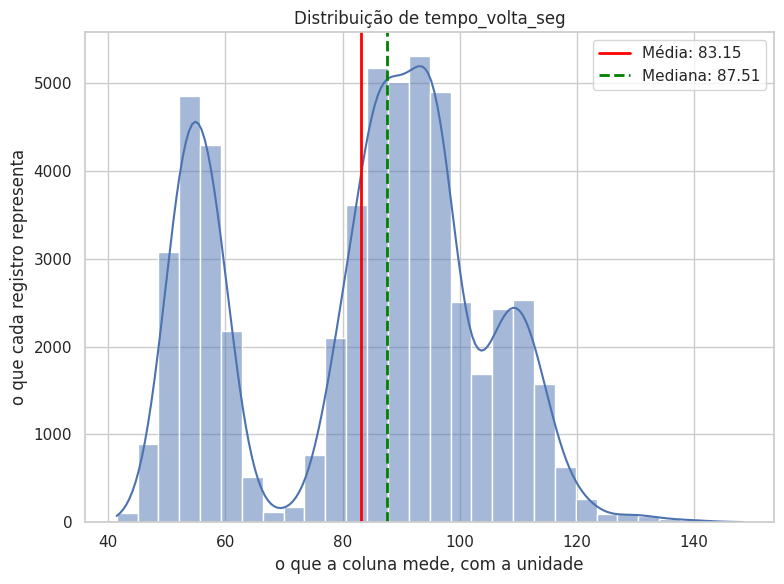

In [70]:
# Histograma: como os valores se distribuem, com a curva da distribuição e as linhas de média e mediana.
sns.histplot(serie_numerica.dropna(), bins=30, kde=True)
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.axvline(serie_numerica.median(), color="green", linestyle="--", linewidth=2, label=f"Mediana: {serie_numerica.median():.2f}")
plt.title(f"Distribuição de {COLUNA_NUMERICA}")
plt.xlabel("o que a coluna mede, com a unidade")        # lacuna: nome do eixo x, em linguagem simples
plt.ylabel("o que cada registro representa")            # lacuna: nome do eixo y, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

Célula 20 · Boxplot


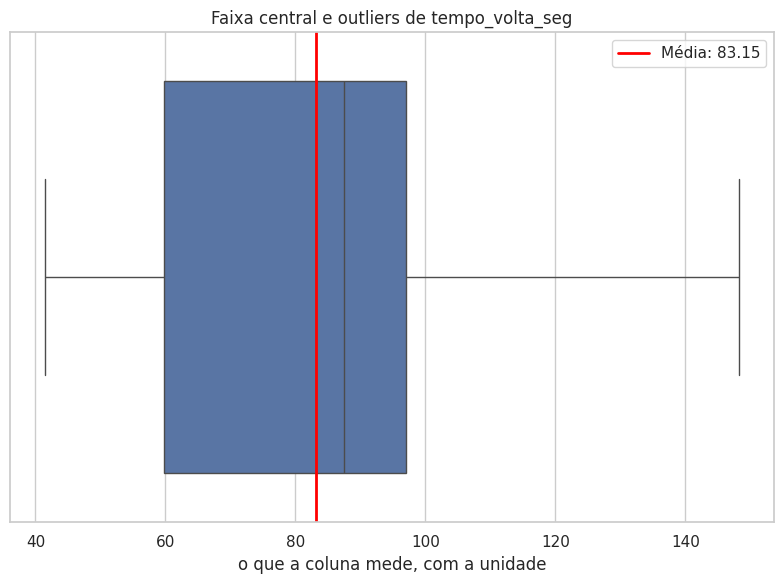

In [71]:
# Boxplot: a caixa é a faixa central (25% a 75%); os pontos fora são candidatos a outlier.
sns.boxplot(x=serie_numerica.dropna())
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.title(f"Faixa central e outliers de {COLUNA_NUMERICA}")
plt.xlabel("o que a coluna mede, com a unidade")        # lacuna: nome do eixo x, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()